# 02 &nbsp;Does a fine-tuned small model beat a prompted large one on the same messages?

**The problem.** A team choosing between fine-tuning a small model and prompting a large hosted one needs to know which gets more answers right on their messages, and by how much. Comparing two headline accuracies measured on different messages mixes up the approaches with the luck of which messages were tested.

**The approach.**

1. Score every option on exactly the same test messages.
2. Compare them in pairs, message by message, with 95% intervals from resampling those messages.
3. Ask a narrower question too: given the *same* 385 labelled examples, is it better to put them in a prompt or to train on them?
4. Read the messages that every option gets wrong, to see how much of the remaining error is the models and how much is the labels.

**The options.**

| Option | What it is | Labelled examples used |
|---|---|---|
| Small model, not fine-tuned | bge-small embeddings (33M parameters) plus logistic regression | all 9,000 |
| Small model, fine-tuned | ModernBERT-base (150M parameters), fine-tuned on a laptop GPU, three runs | all 9,000 |
| Claude Haiku 5.5, prompted | The 77 intent names, with 0, 1 or 5 examples of each in the prompt | 0, 77 or 385 |
| Claude Sonnet 5.5, prompted | The same prompts | 0, 77 or 385 |

To keep the API bill down, Sonnet answered 20 messages of each intent (1,540) instead of all 3,080. Every comparison in this notebook uses those 1,540 messages, so all options face the same questions. Each prompted model was run once; the fine-tuned model's score is the average of its three training runs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fopstudy import plots, style
from fopstudy.data import load_labels, load_split
from fopstudy.evaluate import bootstrap_mean, paired_difference
from fopstudy.results import RESULTS_DIR, correctness, load_predictions

style.use_style()
test = load_split("test")
labels = load_labels()

# Each option's correctness on every message: 0 or 1, or the share of three runs that got it right.
options = {
    "Small model, not fine-tuned": ("frozen", correctness("frozen", "all")),
    "Small model, fine-tuned": ("finetuned", correctness("finetuned", "all", seeds=(0, 1, 2))),
}
for model in ["sonnet", "haiku"]:
    for shots in [5, 1, 0]:
        name = f"{style.APPROACH_LABELS[model].split(',')[0]}, {shots} example{'s' if shots != 1 else ''} per intent"
        options[name] = (model, correctness(model, shots))

rows = options[next(k for k in options if k.startswith("Claude Sonnet"))][1].index  # the 1,540 Sonnet answered
same = pd.DataFrame({name: c.loc[rows] for name, (_, c) in options.items()})
print(f"{len(rows):,} messages, {test.loc[rows, 'label'].value_counts().iloc[0]} of each of the {test.loc[rows, 'label'].nunique()} intents")

1,540 messages, 20 of each of the 77 intents


## 1. Accuracy on the same 1,540 messages

In [2]:
acc = pd.DataFrame([bootstrap_mean(same[name]) for name in same], index=same.columns,
                   columns=["Accuracy", "95% low", "95% high"])
acc.index.name = "Option"
acc.style.format("{:.1%}")

,Accuracy,95% low,95% high
Option,,,
"Small model, not fine-tuned",92.2%,90.8%,93.5%
"Small model, fine-tuned",93.3%,92.2%,94.4%
"Claude Sonnet 5.5, 5 examples per intent",89.9%,88.4%,91.4%
"Claude Sonnet 5.5, 1 example per intent",87.3%,85.6%,89.0%
"Claude Sonnet 5.5, 0 examples per intent",84.0%,82.2%,85.8%
"Claude Haiku 5.5, 5 examples per intent",86.7%,85.0%,88.4%
"Claude Haiku 5.5, 1 example per intent",82.5%,80.6%,84.3%
"Claude Haiku 5.5, 0 examples per intent",79.0%,77.0%,81.0%


## 2. The fine-tuned model against each other option, message by message

Each difference below is the fine-tuned model's accuracy minus the other option's, measured on the same messages. Pairing removes the noise of which messages happen to be easy, so the intervals are much tighter than the overlap of the two separate intervals above would suggest.

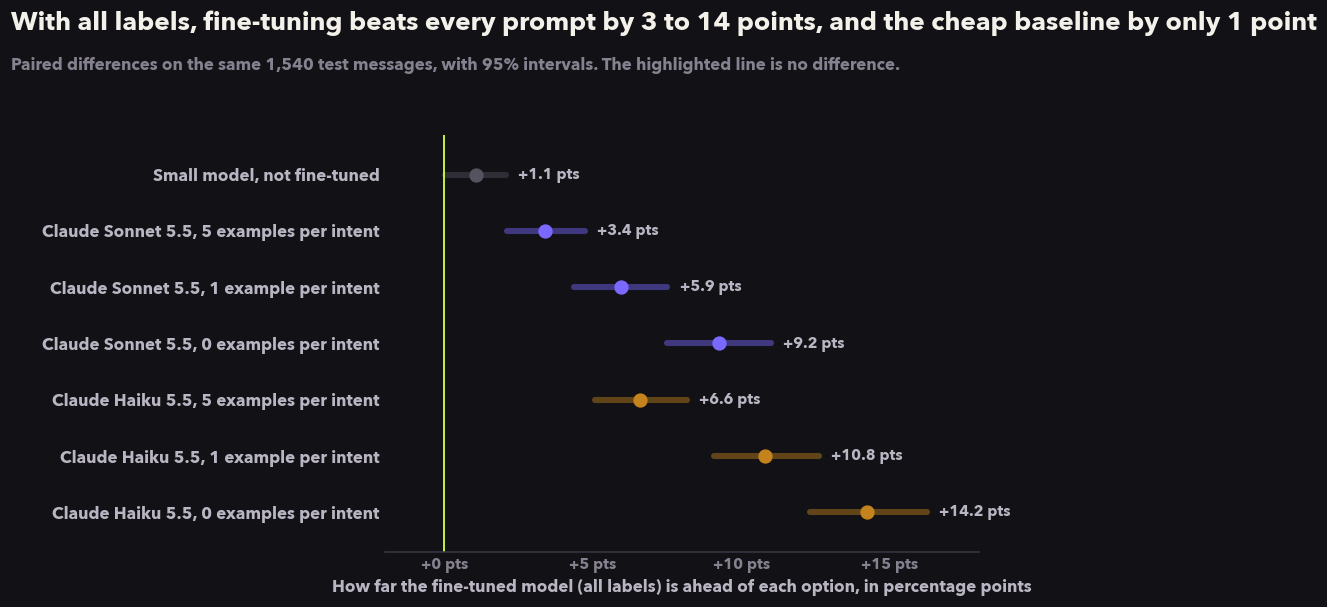

In [3]:
ft = same["Small model, fine-tuned"]
others = [name for name in same if name != "Small model, fine-tuned"]
diff = pd.DataFrame([paired_difference(ft, same[name]) for name in others], index=others,
                    columns=["value", "low", "high"]).reset_index(names="label")
diff["colour"] = [style.APPROACH_COLORS[options[name][0]] for name in diff["label"]]
fig, ax = plots.dot_intervals(diff, value_format=lambda v: f"{v * 100:+.1f} pts")
ax.set_xticks([0, 0.05, 0.10, 0.15])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:+.0f} pts"))
ax.set_xlabel("How far the fine-tuned model (all labels) is ahead of each option, in percentage points")
ax.set_xlim(-0.02, 0.18)
fig.subplots_adjust(top=0.78, left=0.36)
prompted = diff[~diff["label"].str.contains("not fine-tuned")]
style.headline(fig,
               f"With all labels, fine-tuning beats every prompt by {prompted['value'].min() * 100:.0f} to "
               f"{prompted['value'].max() * 100:.0f} points, and the cheap baseline by only "
               f"{diff['value'].iloc[0] * 100:.0f} point",
               "Paired differences on the same 1,540 test messages, with 95% intervals. "
               "The highlighted line is no difference.")
style.save(fig, "finetuned_vs_each_option")

In [4]:
full = paired_difference(correctness("finetuned", "all", seeds=(0, 1, 2)), correctness("frozen", "all"))
print(f"Fine-tuned minus not fine-tuned on all 3,080 test messages: {full[0] * 100:+.1f} points "
      f"(95% interval {full[1] * 100:+.2f} to {full[2] * 100:+.2f})")

Fine-tuned minus not fine-tuned on all 3,080 test messages: +0.7 points (95% interval -0.02 to +1.37)


Against the model that was not fine-tuned, the gap is about one point. On these 1,540 messages its interval only just clears zero, and on the full 3,080 messages it does not, so the two are close to a tie. Among the prompts, more examples and the larger model both help, but even Sonnet with five examples of every intent stays a few points behind.

## 3. The same 385 labelled examples, used three ways

Suppose a team has labelled only 5 messages per intent (385 in all). They can put those examples in the prompt of a hosted model, or train a small model on them. The prompted runs above used exactly the 385 examples that the small models were trained on in their first run, so this is a like-for-like test of what to do with a small labelled set.

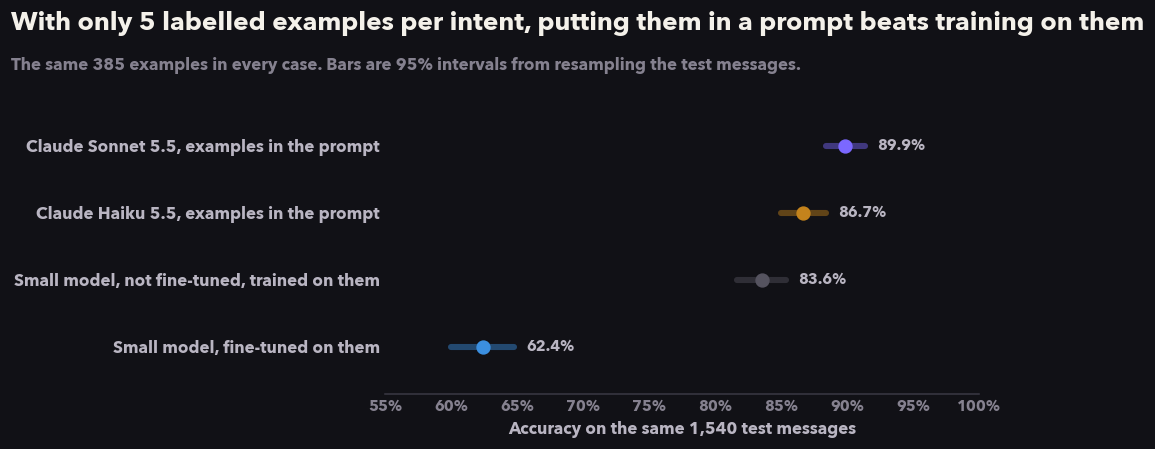

In [5]:
few = pd.DataFrame({
    "Claude Sonnet 5.5, examples in the prompt": correctness("sonnet", 5).loc[rows],
    "Claude Haiku 5.5, examples in the prompt": correctness("haiku", 5).loc[rows],
    "Small model, not fine-tuned, trained on them": correctness("frozen", 5).loc[rows],
    "Small model, fine-tuned on them": correctness("finetuned", 5).loc[rows],
})
few_rows = pd.DataFrame([bootstrap_mean(few[name]) for name in few], columns=["value", "low", "high"])
few_rows["label"] = few.columns
few_rows["colour"] = [style.APPROACH_COLORS[a] for a in ["sonnet", "haiku", "frozen", "finetuned"]]

fig, ax = plots.dot_intervals(few_rows, value_format="{:.1%}", zero_line=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Accuracy on the same 1,540 test messages")
ax.set_xlim(0.55, 1.0)
fig.subplots_adjust(top=0.78, left=0.36)
style.headline(fig, "With only 5 labelled examples per intent, putting them in a prompt beats training on them",
               "The same 385 examples in every case. Bars are 95% intervals from resampling the test messages.")
style.save(fig, "same_385_examples")

In [6]:
gaps = {
    "Haiku prompt minus small model, not fine-tuned": paired_difference(few.iloc[:, 1], few.iloc[:, 2]),
    "Haiku prompt minus small model, fine-tuned": paired_difference(few.iloc[:, 1], few.iloc[:, 3]),
    "Sonnet prompt minus Haiku prompt": paired_difference(few.iloc[:, 0], few.iloc[:, 1]),
}
pd.DataFrame(gaps, index=["Difference", "95% low", "95% high"]).T.style.format(lambda v: f"{v * 100:+.1f} pts")

,Difference,95% low,95% high
"Haiku prompt minus small model, not fine-tuned",+3.1 pts,+1.3 pts,+4.9 pts
"Haiku prompt minus small model, fine-tuned",+24.3 pts,+21.8 pts,+26.8 pts
Sonnet prompt minus Haiku prompt,+3.2 pts,+1.9 pts,+4.4 pts


Fine-tuning a 150M-parameter model on 5 examples per intent works badly: it gets about two in three right, and the three training runs disagree by several points (notebook 03 shows the spread). The same model needs many more labels before training pays off.

## 4. Do the options fail on the same messages?

If the fine-tuned model and a prompted model made different mistakes, a team could combine them, for example by sending the messages they disagree on to a person. The table compares the fine-tuned model (first run) with Haiku given five examples, on the full test set.

In [7]:
a = load_predictions("finetuned", "all", 0).set_index("row")["correct"]
b = load_predictions("haiku", 5, 0).set_index("row")["correct"]
pd.crosstab(a.rename("Fine-tuned (all labels)").map({True: "right", False: "wrong"}),
            b.rename("Haiku, 5 examples").map({True: "right", False: "wrong"}), margins=True, margins_name="Total")

"Haiku, 5 examples",right,wrong,Total
Fine-tuned (all labels),,,
right,2600,268,2868
wrong,87,125,212
Total,2687,393,3080


When Haiku is wrong, the fine-tuned model is usually right. When the fine-tuned model is wrong, Haiku is wrong too more often than not. So the fine-tuned model's mistakes are mostly a subset of hard messages that Haiku also misses, and combining the two would gain little.

In [8]:
any_right = (same > 0).any(axis=1)
none_right = ~any_right
print(f"On the 1,540 messages, at least one of the eight options gets {any_right.mean():.1%} right; "
      f"{none_right.sum()} messages are missed by every option.")

On the 1,540 messages, at least one of the eight options gets 97.8% right; 34 messages are missed by every option.


## 5. Reading the messages that every option gets wrong

Notebook 01 found that the most common errors are between look-alike intents and asked whether some are labelling problems rather than model mistakes. Here, the messages missed by all four main options (the two small models trained on all labels, and Haiku and Sonnet with five examples) were read one by one and given one of three verdicts:

- **Label looks wrong**: another intent fits the message clearly better than its label (most often the one the models chose).
- **Ambiguous**: the message is too short or vague to pick one intent; the label and the models' answer are both defensible.
- **Models wrong**: the label is right and the models missed it.

The verdicts are in [results/hand_check.csv](../results/hand_check.csv).

In [9]:
main = ["Small model, not fine-tuned", "Small model, fine-tuned",
        "Claude Sonnet 5.5, 5 examples per intent", "Claude Haiku 5.5, 5 examples per intent"]
all_miss = same.index[(same[main] == 0).all(axis=1)]
check = pd.read_csv(RESULTS_DIR / "hand_check.csv").set_index("row")
assert set(check.index) == set(all_miss), "hand check must cover exactly the messages every option misses"

verdicts = check["verdict"].value_counts()
pd.DataFrame({"Messages": verdicts, "Share of the 1,540": verdicts / len(rows)}).rename_axis("Verdict").style.format(
    {"Share of the 1,540": "{:.1%}"})

,Messages,"Share of the 1,540"
Verdict,,
label looks wrong,23,1.5%
ambiguous,15,1.0%
models wrong,1,0.1%


In [10]:
shown = check[check["verdict"] != "ambiguous"].head(6).index.tolist() + \
        check[check["verdict"] == "ambiguous"].head(3).index.tolist()
sonnet5 = load_predictions("sonnet", 5, 0).set_index("row")
pd.DataFrame({
    "Message": test.loc[shown, "text"].to_numpy(),
    "Label": [labels[i].replace("_", " ") for i in test.loc[shown, "label"]],
    "Sonnet's answer": [labels[i].replace("_", " ") for i in sonnet5.loc[shown, "pred"]],
    "Verdict": check.loc[shown, "verdict"].to_numpy(),
}).style.hide(axis="index")

Message,Label,Sonnet's answer,Verdict
How long does a card delivery take?,card arrival,card delivery estimate,label looks wrong
"There is an incoming payment into my account, but it is deactivated. Will they still be processed?",fiat currency support,receiving money,label looks wrong
Am I able to exchange currencies?,fiat currency support,exchange via app,label looks wrong
my card was not in the mail again can you advise?,card delivery estimate,card arrival,label looks wrong
Will declined funds I tried to withdraw be returned to me?,wrong amount of cash received,declined cash withdrawal,label looks wrong
When will my funds transfer?,transfer not received by recipient,transfer timing,label looks wrong
When will I get my card?,card arrival,card delivery estimate,ambiguous
Why am I being charged more ?,card payment wrong exchange rate,extra charge on statement,ambiguous
My account was charged for a withdraw I tried to make that was decline.,pending cash withdrawal,declined cash withdrawal,ambiguous


In [11]:
wrong_label = (check["verdict"] == "label looks wrong").sum()
unclear = (check["verdict"] == "ambiguous").sum()
best = acc["Accuracy"].max()
print(f"{wrong_label} of the 1,540 labels ({wrong_label / len(rows):.1%}) look wrong and {unclear} more "
      f"({unclear / len(rows):.1%}) are ambiguous. If those count as unanswerable, the best option's "
      f"{best:.1%} sits about {(1 - best) * 100 - (wrong_label + unclear) / len(rows) * 100:.1f} points "
      f"below what is reachable, not {(1 - best) * 100:.1f}.")

23 of the 1,540 labels (1.5%) look wrong and 15 more (1.0%) are ambiguous. If those count as unanswerable, the best option's 93.3% sits about 4.3 points below what is reachable, not 6.7.


Most of what every option gets wrong is not a model failure. A few percent of Banking77's test labels are wrong or arguable, so no approach can reach 100%, and differences of a point or two near the top deserve less weight than they seem to. This check covers only the messages all four options miss; labels that are wrong where some option agrees with them are not counted, so the true share of bad labels is somewhat higher.

## What this means

- **With plenty of labels, the fine-tuned small model wins on quality.** With all 9,000 labelled examples it beats every prompted option, including Sonnet with five examples per intent, on the same messages.
- **But the model that was not fine-tuned is almost as good.** A frozen embedding model with a linear classifier, trained in seconds, is about one point behind, a gap at the edge of what 3,080 test messages can detect. Fine-tuning has to justify its training run against that, not against the prompts.
- **With few labels, prompting wins clearly.** Given the same 385 examples, Haiku with the examples in its prompt beats both small models trained on them, and Sonnet is better still. A team that has not labelled much should prompt first.
- **The hard messages are hard for everyone.** The options mostly fail on the same messages, and most of those are mislabelled or ambiguous. That caps every approach a few points below 100%.

**What the data can't tell us.** Each prompted model was run once, so the variation between reruns of the same prompt is not measured here. The verdicts in section 5 are one reader's judgement. And this is one short-message classification task; tasks with longer inputs, or where the hosted model's general knowledge matters, could favour prompting more.